# Exercise: life without oxygen

*E. coli* lives in our gut, where there is hardly any oxygen. Can it grow there? And what changes?

Run the first two cells to set up.

In [1]:
setLanguage('en')   % language of the messages below

Language: English


In [2]:
model = loadEcoli();

Model loaded: E. coli core model with 95 reactions, 72 metabolites and 137 genes.


## With oxygen

`setMedium(model, glucose, oxygen)` sets how much glucose and oxygen the cells may take up at most. 1000 means "as much as they want".

In [3]:
model_air = setMedium(model, 10, 1000);
[growth_air, solution_air] = showGrowth(model_air);

Food: glucose uptake up to 10, oxygen uptake up to 1000 (mmol per gram per hour).
Growth rate: 0.874 per hour (the cells double every 48 minutes).


## Without oxygen

Now take the oxygen away. Replace `___` with the right number.

In [4]:
model_no_air = setMedium(model, 10, 0);
[growth_no_air, solution_no_air] = showGrowth(model_no_air);

Food: glucose uptake up to 10, oxygen uptake up to 0 (mmol per gram per hour).
Growth rate: 0.212 per hour (the cells double every 196 minutes).


**Question 1:** Can *E. coli* grow without oxygen? How many times slower is it? *(Tip: you can calculate in a code cell, e.g. `growth_air / growth_no_air`.)*

In [5]:
growth_air / growth_no_air

ans = 4.1288


✅ **Answer:** Yes, it still grows, but about **4 times slower**: 0.212 instead of 0.874 per hour. It doubles every 196 minutes instead of every 48 minutes.

## What comes out without oxygen?

In [6]:
showExchange(model_no_air, solution_no_air)

The cells TAKE UP:
  glucose (sugar)                 10.00
  water                            7.12
  ammonium (nitrogen)              1.15
  phosphate                        0.78
  carbon dioxide (CO2)             0.38
The cells RELEASE:
  H+ (acidity)                    30.55
  formate                         17.80
  acetate (vinegar acid)           8.50
  ethanol (alcohol)                8.28


**Question 2:** Which substances does *E. coli* release now that it didn't release with oxygen? Do you know any of them from everyday life?

✅ **Answer:** **Formate** (formic acid, known from ant stings), **acetate** (the acid in vinegar) and **ethanol** (the alcohol in beer and wine). This is called **fermentation**. Yeast does the same to make bread rise and to brew beer, and your muscles make lactic acid when they run out of oxygen.

**Why?** With oxygen, the cell can "burn" glucose completely to CO₂ and get a lot of energy (ATP) from it. Without oxygen it can only break glucose down halfway. It gets much less energy, and the half-used molecules are released as waste. Less energy means slower growth.

## How much oxygen is enough?

The cell below calculates the growth rate for many different amounts of oxygen and draws a graph. Just run it.

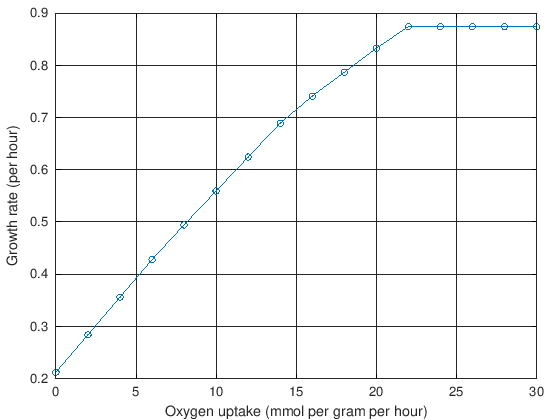

In [7]:
oxygen = 0:2:30;                      % 0, 2, 4, ... 30
growth = zeros(size(oxygen));
for i = 1:numel(oxygen)
  m = changeRxnBounds(model, 'EX_o2_e', -oxygen(i), 'l');   % allow this much oxygen
  s = optimizeCbModel(m);                                     % run FBA
  growth(i) = s.f;                                            % remember the growth rate
end
plot(oxygen, growth, 'o-', 'linewidth', 2)
xlabel('Oxygen uptake (mmol per gram per hour)')
ylabel('Growth rate (per hour)')
grid on

**Question 3:** Describe the graph. From what amount of oxygen does extra oxygen stop helping? Why does the line become flat?

✅ **Answer:** Growth rises steadily with oxygen and becomes flat at about **22** units. From there on, glucose is the limit: the cell already burns all 10 units of sugar it can take up, and extra oxygen has nothing left to burn.

## One best way, or many good ones?
FBA gives you **one** set of fluxes for the fastest possible growth. But is that the only way the cell can do it? **Flux variability analysis (FVA)** checks every reaction: what is the **smallest** and the **largest** flux it can have while the cells still grow as fast as before?

`showFluxRange(model, percent, reactions)` does this for a few reactions. `percent` is how fast the cells must still grow: 100 means at full speed. A **negative** flux means the reaction runs backwards. For exchange reactions (`EX_…`) it means the substance is taken up instead of released.

Flux ranges while the cells grow at least 100% of their maximum (0.874 per hour or more):
  reaction   smallest  largest
  PGI            4.86     4.86   Glucose-6-phosphate isomerase   <- fixed
  G6PDH2r        4.96     4.96   Glucose 6-phosphate dehydrogenase   <- fixed
  EX_o2_e      -21.80   -21.80   oxygen (O2)   <- fixed
  EX_ac_e        0.00     0.00   acetate (vinegar acid)   <- fixed
  EX_etoh_e      0.00     0.00   ethanol (alcohol)   <- fixed
  EX_for_e       0.00     0.00   formate   <- fixed


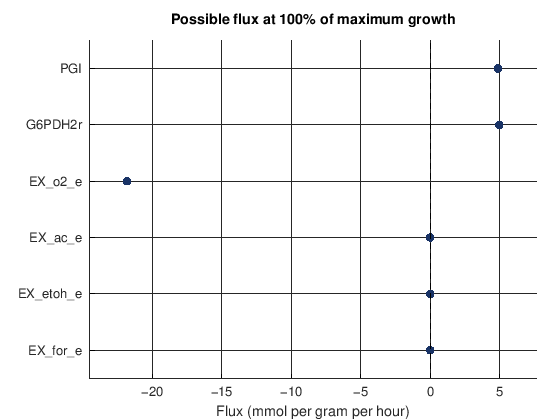

In [8]:
reactions = {'PGI', 'G6PDH2r', 'EX_o2_e', 'EX_ac_e', 'EX_etoh_e', 'EX_for_e'};
showFluxRange(model_air, 100, reactions);

**Question 4:** Compare the smallest and the largest flux of each reaction. What does that tell you about how the cell grows at full speed?

✅ **Answer:** They are the same for every reaction: each flux is **fixed**. At full speed there is only **one** way to grow, so the cell has no choices at all.

Now let the cells grow a little slower: at least **90 %** of full speed. Replace `___` with the right number.

Flux ranges while the cells grow at least 90% of their maximum (0.787 per hour or more):
  reaction   smallest  largest
  PGI          -14.30     9.84   Glucose-6-phosphate isomerase
  G6PDH2r        0.00    24.14   Glucose 6-phosphate dehydrogenase
  EX_o2_e      -25.62   -17.99   oxygen (O2)
  EX_ac_e        0.00     3.81   acetate (vinegar acid)
  EX_etoh_e      0.00     2.21   ethanol (alcohol)
  EX_for_e       0.00    11.32   formate


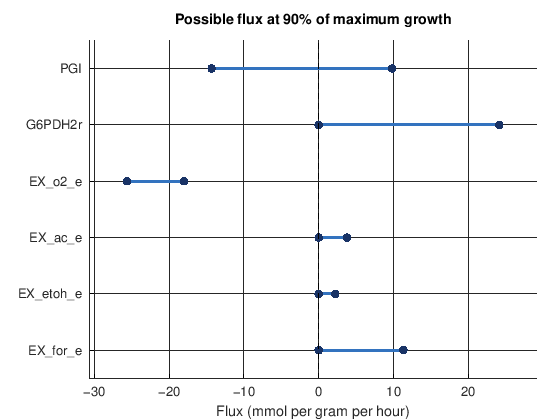

In [9]:
showFluxRange(model_air, 90, reactions);

**Question 5:** What changed? Which substances *could* the cells now release, even though they have plenty of oxygen?

✅ **Answer:** Every reaction now has a **range**: giving up just 10 % of growth opens up many different routes. PGI can even run backwards. The cells could release **acetate** (up to 3.8), **ethanol** (up to 2.2) and **formate** (up to 11.3), and use less oxygen. Real *E. coli* does exactly this: when it grows fast on glucose, it releases acetate even with oxygen around (*overflow metabolism*). FBA alone, which only looks at the single fastest way, misses this.

Now do the same without oxygen.

Flux ranges while the cells grow at least 90% of their maximum (0.190 per hour or more):
  reaction   smallest  largest
  PGI            7.03     9.96   Glucose-6-phosphate isomerase
  G6PDH2r        0.00     2.93   Glucose 6-phosphate dehydrogenase
  EX_o2_e        0.00     0.00   oxygen (O2)   <- fixed
  EX_ac_e        0.46     8.65   acetate (vinegar acid)
  EX_etoh_e      5.90    16.10   ethanol (alcohol)
  EX_for_e       2.74    18.02   formate


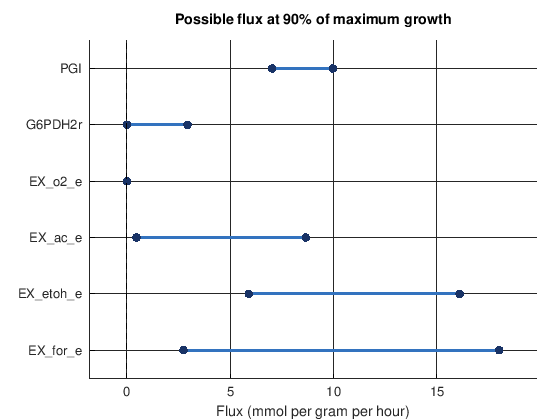

In [10]:
showFluxRange(model_no_air, 90, reactions);

**Question 6:** Look at the **smallest** flux of acetate, ethanol and formate. What does it tell you about life without oxygen?

✅ **Answer:** Without oxygen the smallest values are **above 0**: the cells **must** release all three, whichever route they take. Fermentation isn't one option among many, it is the only way to grow without oxygen.

**Done!** Continue with `03_exercise_food.ipynb`.

<small>Model: *E. coli* core model from BiGG Models (Orth et al. 2010; King et al. 2016). Software: COBRA Toolbox (Heirendt et al. 2019) in GNU Octave. Full sources at the end of `01_tutorial_fba.ipynb`.</small>